# 03. 문제해결: 가위바위보 승부 판정 Graph
## 학습 목표
- 두 State 값(`player`, `computer`)을 비교하는 Routing 함수를 만든다.
- `add_conditional_edges()`로 세 갈래(승리/패배/무승부) 경로를 구성한다.

**핵심 개념**: 03번의 점수 분기와 구조는 같다. 다른 점은 Routing 함수가 값 하나가 아니라 **두 값의 조합**을 보고 다음 Node를 정한다는 것이다. API 키는 필요하지 않다.

## 실행 전 예측
- `player`와 `computer`가 같으면 어느 경로로 가야 할까?
- 3×3 = 9가지 경우를 if문 몇 개로 줄일 수 있을까? "이기는 조합"만 집합으로 정의하면 `무승부 → 승리 → 나머지는 패배` 순서로 판단할 수 있다.

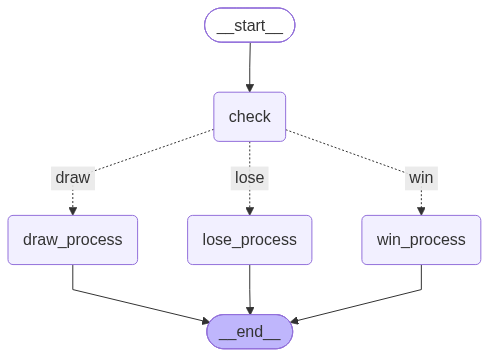

In [7]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph

# State 스키마 정의
# State 이름 : RSPState
# player: str   ("가위", "바위", "보" 중 하나)
# computer: str ("가위", "바위", "보" 중 하나)
# result: str
class RSPState(TypedDict):
    player: str
    computer: str
    result: str

# 이기는 조합(player, computer)만 집합으로 정의한다.
# 가위는 보를, 바위는 가위를, 보는 바위를 이긴다.
WIN_CASES = {("가위", "보"), ("바위", "가위"), ("보", "바위")}

# Node 정의
def check_node(state: RSPState) -> dict:
    print(f"check_node 실행:  {state["player"]} vs {state["computer"]}")
    return {"player": state["player"]}

def win_node(state: RSPState) -> dict:
    # 승리 프린트
    print("승리")
    return {"result": "승리"}

def lose_node(state: RSPState) -> dict:
    # 패배 프린트
    print("패배")
    return {"result": "패배"}

def draw_node(state: RSPState) -> dict:
    # 무승부 프린트
    print("무승부")
    return {"result": "무승부"}


# 조건에 따라 다음 Node를 결정하는 라우팅 함수 정의
# 같은 손이면 무승부, 이기는 조합에 있으면 승리, 나머지는 모두 패배이다.
def route(state: RSPState) -> str:
    if state["player"] == state["computer"]:
        return "draw"
    if (state["player"], state["computer"]) in WIN_CASES:
        return "win"
    return "lose"


# Graph builder 생성
builder3 = StateGraph(RSPState)

# Node를 Graph에 등록
builder3.add_node("check", check_node)
builder3.add_node("win_process", win_node)
builder3.add_node("lose_process", lose_node)
builder3.add_node("draw_process", draw_node)

# Edge 연결
builder3.add_edge(START, "check")
builder3.add_conditional_edges(
    # 어떤 노드에서 실행
    "check",
    # 어떤 판단으로 라우팅이되는가? => 라우팅 함수
    route,
    # 라우팅 map
    # {"판단한 결과값": "실행 노드"}
    {"win": "win_process",
     "lose": "lose_process",
     "draw": "draw_process"
     }
)
builder3.add_edge("win_process", END)
builder3.add_edge("lose_process", END)
builder3.add_edge("draw_process", END)

# Graph 컴파일
graph = builder3.compile()
graph

## 한 판 실행해보기

In [8]:
game = ("가위", "보", "")
result = graph.invoke({"player": game[0], "computer": game[1], "result": game[2]})

result

check_node 실행:  가위 vs 보
승리


{'player': '가위', 'computer': '보', 'result': '승리'}

## 자가 점검용 테스트

In [9]:
# 테스트 데이터 (player, computer, 기대 result)
games = [
    ("가위", "보", "승리"),
    ("가위", "바위", "패배"),
    ("가위", "가위", "무승부"),
    ("바위", "가위", "승리"),
    ("보", "바위", "승리"),
    ("보", "가위", "패배"),
]

# 테스트 실행
for player, computer, expected in games:
    print(f"\n입력: {player} vs {computer}")
    result = graph.invoke({"player": player, "computer": computer, "result": "미정"})
    print("최종 State:", result)
    assert result["result"] == expected


입력: 가위 vs 보
check_node 실행:  가위 vs 보
승리
최종 State: {'player': '가위', 'computer': '보', 'result': '승리'}

입력: 가위 vs 바위
check_node 실행:  가위 vs 바위
패배
최종 State: {'player': '가위', 'computer': '바위', 'result': '패배'}

입력: 가위 vs 가위
check_node 실행:  가위 vs 가위
무승부
최종 State: {'player': '가위', 'computer': '가위', 'result': '무승부'}

입력: 바위 vs 가위
check_node 실행:  바위 vs 가위
승리
최종 State: {'player': '바위', 'computer': '가위', 'result': '승리'}

입력: 보 vs 바위
check_node 실행:  보 vs 바위
승리
최종 State: {'player': '보', 'computer': '바위', 'result': '승리'}

입력: 보 vs 가위
check_node 실행:  보 vs 가위
패배
최종 State: {'player': '보', 'computer': '가위', 'result': '패배'}


Routing 함수는 `player`와 `computer`를 함께 읽어 `"win"`, `"lose"`, `"draw"` 중 하나를 반환하고, 라우팅 map이 이 값을 실제 Node 이름으로 연결한다.  
한 실행에서는 세 결과 Node 중 하나만 방문한다.

## 이해 확인
1. `route`에서 무승부 검사를 가장 먼저 하는 이유는 무엇인가?  
   **해설:** 같은 손은 이기는 조합에도, 지는 조합에도 속하지 않는다. 먼저 걸러내야 "나머지는 패배"라는 마지막 규칙이 성립한다.
2. 9가지 경우를 모두 if문으로 쓰지 않아도 되는 이유는?  
   **해설:** 무승부 3가지는 `==` 한 번으로, 승리 3가지는 `WIN_CASES` 집합으로 처리하면 남은 3가지는 자동으로 패배이다.

**핵심 정리:** 조건부 Edge의 Routing 함수는 State의 여러 필드를 조합해 판단할 수 있다. 판단 규칙은 Routing 함수에, 결과별 처리는 각 Node에 나눠 둔다.